In [1]:
import onnx
from pathlib import Path
import sys
sys.path.append("..")
import onnxruntime as ort
import numpy as np
import onnxruntime
import os


In [2]:
BASE_PATH = Path('..')
DATA_PATH = BASE_PATH / 'val2017'
MODEL_PATH = BASE_PATH / 'data' / 'models' / 'yolov8n_b1.onnx'

In [3]:
onnx_model = onnx.load(MODEL_PATH)
onnx.checker.check_model(onnx_model)

Text(0.5, 1.0, 'After internal Letterbox')

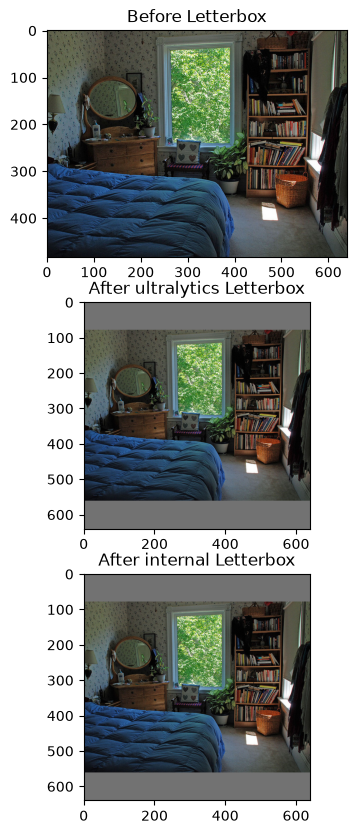

In [19]:
from ultralytics.data.augment import LetterBox
import cv2
import matplotlib.pyplot as plt
sys.path.append("../scripts/common_py.py")
from scripts.common_py import letterbox

IMAGE_IDX = 2

filenames = sorted(os.listdir(DATA_PATH))
image_data = cv2.imread(DATA_PATH / filenames[IMAGE_IDX])

lb = LetterBox(new_shape=(640,640), auto=False)
boxed = lb(image=image_data)[:,:,::-1]

internal_boxed = letterbox(DATA_PATH / filenames[IMAGE_IDX])





plt.figure(figsize=(60, 10))
plt.subplot(3, 1, 2)

plt.imshow(boxed)
plt.title("After ultralytics Letterbox")

plt.subplot(3, 1, 1)
plt.imshow(image_data[:,:,::-1])
plt.title("Before Letterbox")

plt.subplot(3, 1, 3)
plt.imshow(internal_boxed.transpose(1, 2, 0))
plt.title("After internal Letterbox")